<a href="https://colab.research.google.com/github/gautambajaj18/Retail-Inventory-Demand-Forecasting/blob/main/Retail_Inventory_EDA_and_Demand_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
## 1. Load the Data
import pandas as pd

df= pd.read_csv("retail_store_inventory.csv")


In [ ]:
## 2. Preview the First 5 Rows
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [ ]:
## 3. Check Rows, Columns and Data Types
print(df.shape)
df.info()

(73100, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory

In [ ]:
## 4. Check for Missing Values and Duplicates
print(df.isnull().sum())
print(df.duplicated().sum())

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64
0


In [ ]:
## 5. Clean Column Names
df.columns = df.columns.str.replace(" ", "_").str.replace("/", "_")
df.columns

Index(['Date', 'Store_ID', 'Product_ID', 'Category', 'Region',
       'Inventory_Level', 'Units_Sold', 'Units_Ordered', 'Demand_Forecast',
       'Price', 'Discount', 'Weather_Condition', 'Holiday_Promotion',
       'Competitor_Pricing', 'Seasonality'],
      dtype='object')

In [ ]:
## 6. Convert Date and Extract Month and Year
df["Date"]=pd.to_datetime(df["Date"])
df["Month"]= df["Date"].dt.month
df["Year"]=df["Date"].dt.year
df[["Date","Month","Year"]].head()

,Date,Month,Year
0,2022-01-01,1,2022
1,2022-01-01,1,2022
2,2022-01-01,1,2022
3,2022-01-01,1,2022
4,2022-01-01,1,2022


In [ ]:
## 7. Total Sales by Category
df.groupby("Category")["Units_Sold"].sum().sort_values(ascending=False)

,Units_Sold
Category,
Furniture,2025017
Groceries,2000482
Clothing,1999166
Toys,1990485
Electronics,1960432


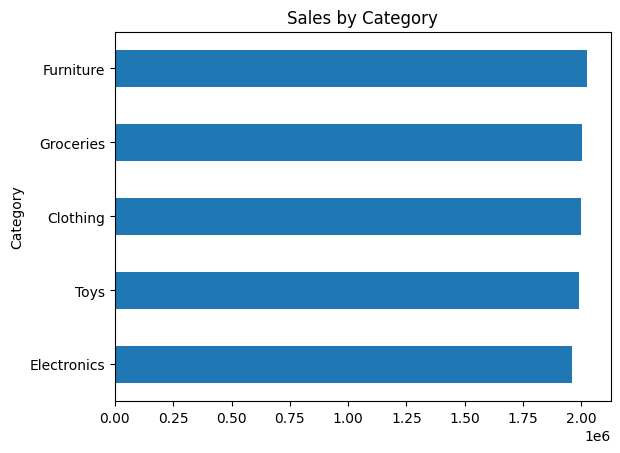

In [ ]:
## 8. Sales by Category (Chart)
import matplotlib.pyplot as plt

df.groupby("Category")["Units_Sold"].sum().sort_values().plot(kind="barh")
plt.title("Sales by Category")
plt.show()

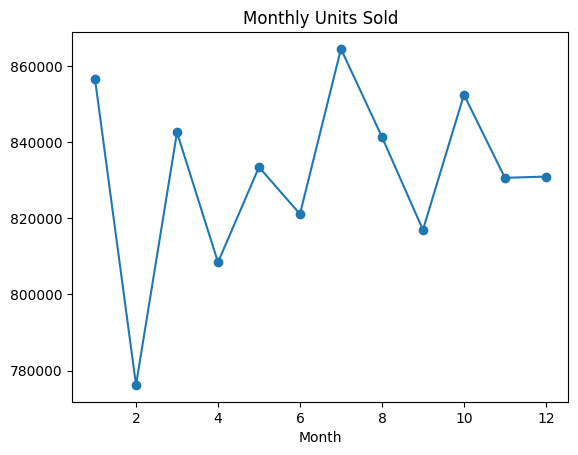

In [ ]:
## 9. Monthly Sales Trend
df.groupby("Month")["Units_Sold"].sum().plot(kind="line", marker="o")
plt.title("Monthly Units Sold")
plt.show()

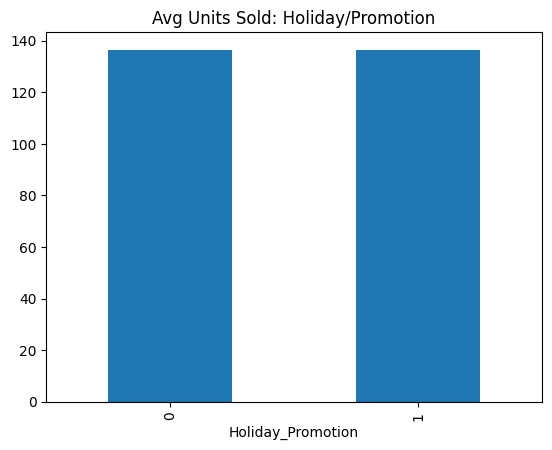

In [ ]:
## 10. Effect of Holiday/Promotion on Sales
df.groupby("Holiday_Promotion")["Units_Sold"].mean().plot(kind="bar")
plt.title("Avg Units Sold: Holiday/Promotion")
plt.show()

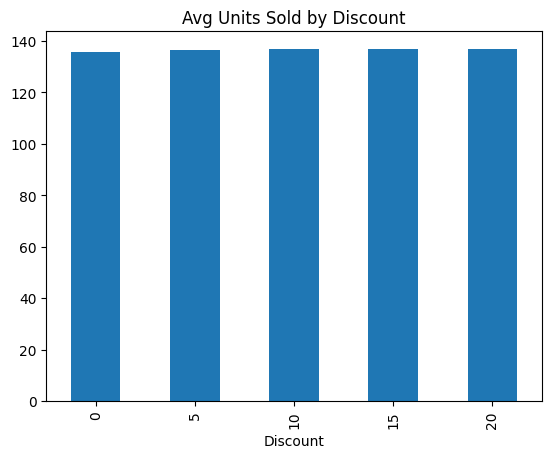

In [ ]:
## 11. Effect of Discount on Sales
df.groupby("Discount")["Units_Sold"].mean().plot(kind="bar")
plt.title("Avg Units Sold by Discount")
plt.show()

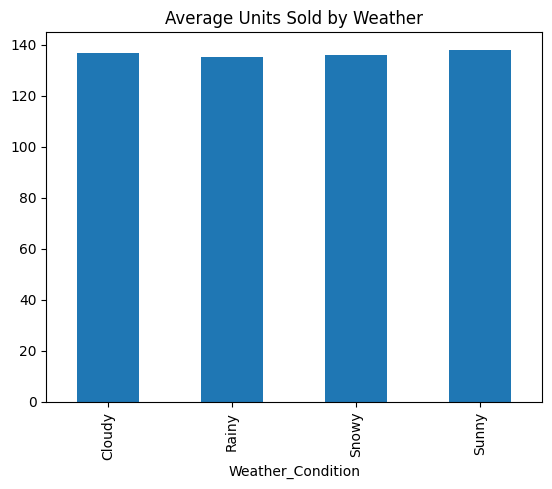

In [ ]:
## 12. Effect of Weather on Sales
df.groupby("Weather_Condition")["Units_Sold"].mean().plot(kind="bar")
plt.title("Average Units Sold by Weather")
plt.show()

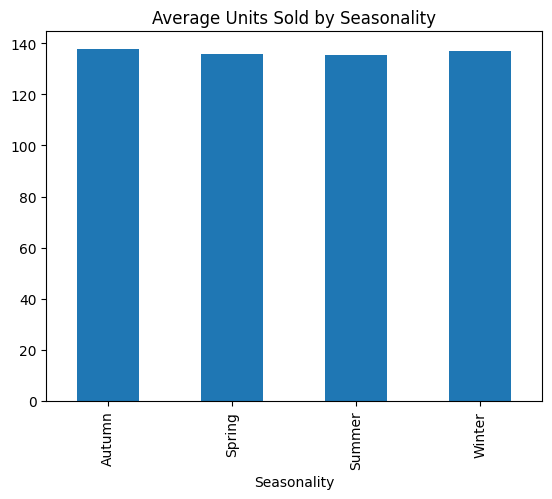

In [ ]:
## 13. Effect of Seasonality on Sales
df.groupby("Seasonality")["Units_Sold"].mean().plot(kind="bar")
plt.title("Average Units Sold by Seasonality")
plt.show()

In [ ]:
## 14. Stock-out Check (Inventory < Units Sold)
df["Stockout_Risk"] = df["Inventory_Level"] < df["Units_Sold"]
print(df["Stockout_Risk"].mean() * 100)

0.0


In [ ]:
## 15. Stock-out Re-check (Sum, Min, Max)
print(df["Stockout_Risk"].sum())
print(df["Inventory_Level"].min(), df["Units_Sold"].max())

0
50 499


In [ ]:
## 16. Stock Left After Sales
df["Stock_Left"] = df["Inventory_Level"] - df["Units_Sold"]
df["Stock_Left"].describe()

,Stock_Left
count,73100.000000
mean,138.005007
std,109.766664
min,0.000000
25%,49.000000
50%,109.000000
75%,205.000000
max,500.000000


In [ ]:
## 17. Demand Forecast Error (Average)
df["Forecast_Error"] = (df["Units_Sold"] - df["Demand_Forecast"]).abs()
print(df["Forecast_Error"].mean())

8.338075512995896


In [ ]:
## 18. Average Units Sold
print(df["Units_Sold"].mean())

136.46487004103966


In [ ]:
## 19. Forecast Error as a Percentage
print(df["Forecast_Error"].mean() / df["Units_Sold"].mean() * 100)

6.110052726748175


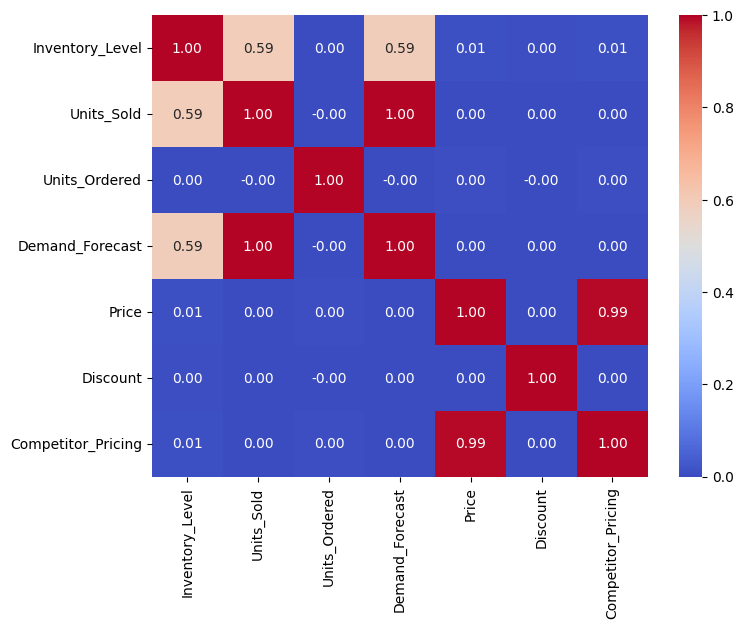

In [ ]:
## 20. Correlation Heatmap
import seaborn as sns

cols = ["Inventory_Level", "Units_Sold", "Units_Ordered", "Demand_Forecast", "Price", "Discount", "Competitor_Pricing"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

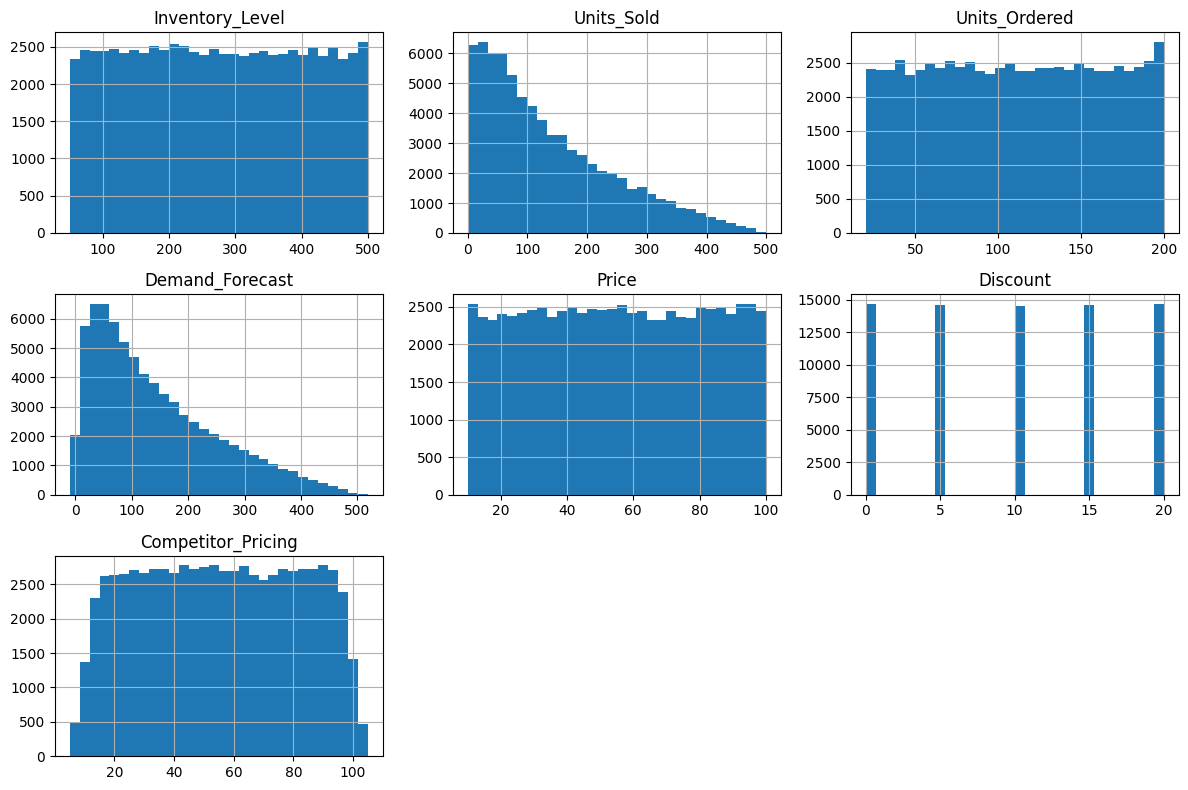

In [ ]:
## 21. Distribution of Numeric Columns (Histogram)
df[cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

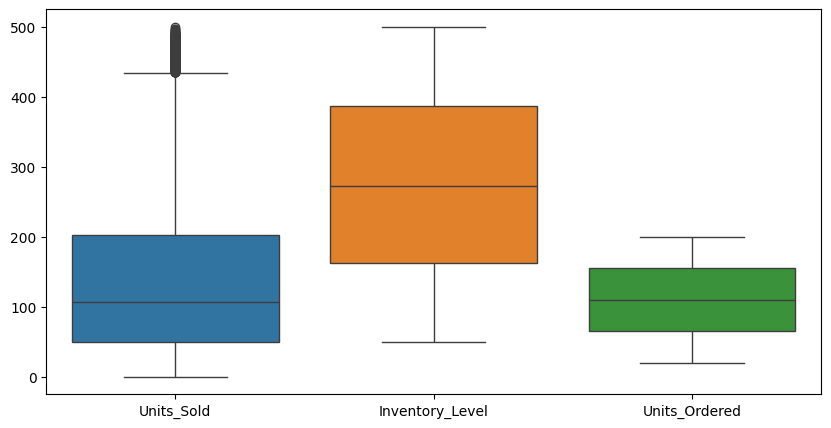

In [ ]:
## 22. Outlier Detection (Boxplot)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[["Units_Sold", "Inventory_Level", "Units_Ordered"]])
plt.show()

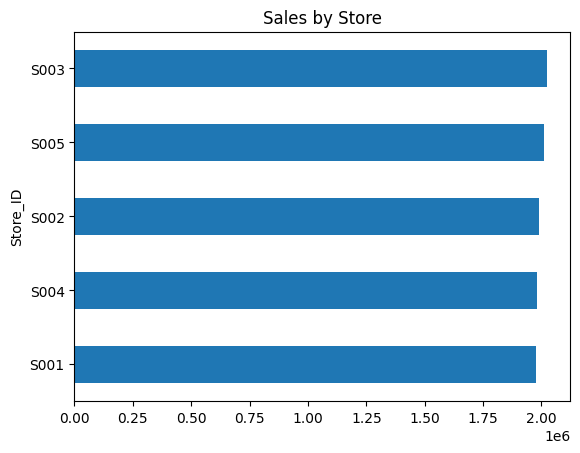

In [ ]:
## 23. Sales by Store
df.groupby("Store_ID")["Units_Sold"].sum().sort_values().plot(kind="barh")
plt.title("Sales by Store")
plt.show()

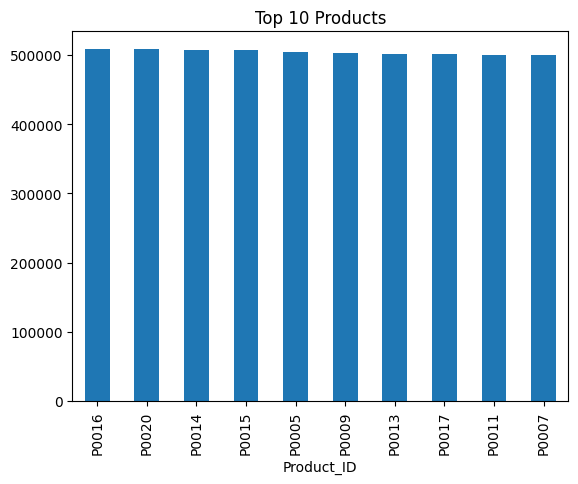

In [ ]:
## 24. Top 10 Products
df.groupby("Product_ID")["Units_Sold"].sum().sort_values(ascending=False).head(10).plot(kind="bar")
plt.title("Top 10 Products")
plt.show()

In [ ]:
## 25. Summary Numbers for Insights
print("Category:\n", df.groupby("Category")["Units_Sold"].sum().sort_values(ascending=False), "\n")
print("Region:\n", df.groupby("Region")["Units_Sold"].sum().sort_values(ascending=False), "\n")
print("Holiday:\n", df.groupby("Holiday_Promotion")["Units_Sold"].mean(), "\n")
print("Discount:\n", df.groupby("Discount")["Units_Sold"].mean(), "\n")
print("Weather:\n", df.groupby("Weather_Condition")["Units_Sold"].mean(), "\n")
print("Season:\n", df.groupby("Seasonality")["Units_Sold"].mean(), "\n")
print("Store:\n", df.groupby("Store_ID")["Units_Sold"].sum().sort_values(ascending=False).head(3), "\n")
print("Product:\n", df.groupby("Product_ID")["Units_Sold"].sum().sort_values(ascending=False).head(3), "\n")
print("Corr Units_Sold vs Demand_Forecast:", df["Units_Sold"].corr(df["Demand_Forecast"]))
print("Corr Units_Sold vs Price:", df["Units_Sold"].corr(df["Price"]))
print("Corr Units_Sold vs Discount:", df["Units_Sold"].corr(df["Discount"]))

Category:
 Category
Furniture      2025017
Groceries      2000482
Clothing       1999166
Toys           1990485
Electronics    1960432
Name: Units_Sold, dtype: int64 

Region:
 Region
East     2511265
South    2507799
North    2484966
West     2471552
Name: Units_Sold, dtype: int64 

Holiday:
 Holiday_Promotion
0    136.505375
1    136.423926
Name: Units_Sold, dtype: float64 

Discount:
 Discount
0     135.694585
5     136.567405
10    136.769851
15    136.655293
20    136.640775
Name: Units_Sold, dtype: float64 

Weather:
 Weather_Condition
Cloudy    136.758324
Rainy     135.160028
Snowy     135.911559
Sunny     138.028650
Name: Units_Sold, dtype: float64 

Season:
 Seasonality
Autumn    137.782444
Spring    135.826828
Summer    135.428298
Winter    136.830790
Name: Units_Sold, dtype: float64 

Store:
 Store_ID
S003    2022696
S005    2010176
S002    1987715
Name: Units_Sold, dtype: int64 

Product:
 Product_ID
P0016    508472
P0020    507708
P0014    507622
Name: Units_Sold, dtype: i

In [ ]:
## 27. Create Features (X) and Target (y)
y = df["Units_Sold"]

X = df.drop(columns=["Units_Sold", "Demand_Forecast", "Forecast_Error", "Stock_Left", "Stockout_Risk", "Date"])

X = pd.get_dummies(X, drop_first=True)

print(X.shape)

(73100, 44)


In [ ]:
## 28. Train-Test Split (Time-based, 80/20)
cutoff = df["Date"].quantile(0.8)
train_mask = df["Date"] <= cutoff

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print(X_train.shape, X_test.shape)

(58500, 44) (14600, 44)


In [ ]:
## 29. Baseline Model: Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred))
print("Avg Units Sold (test):", y_test.mean())

MAE: 68.65744897511445
Avg Units Sold (test): 135.88417808219177


In [ ]:
## 30. Random Forest Model
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("RF MAE:", mean_absolute_error(y_test, rf_pred))


RF MAE: 69.61278219178082


In [ ]:
## 31. Model Comparison (Dataset Forecast vs Linear vs Random Forest)
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

forecast_test = df.loc[~train_mask, "Demand_Forecast"]

results = pd.DataFrame({
    "Model": ["Dataset Forecast", "Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, forecast_test),
        mean_absolute_error(y_test, pred),
        mean_absolute_error(y_test, rf_pred),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, forecast_test)),
        np.sqrt(mean_squared_error(y_test, pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred)),
    ],
    "R2": [
        r2_score(y_test, forecast_test),
        r2_score(y_test, pred),
        r2_score(y_test, rf_pred),
    ],
})
results

,Model,MAE,RMSE,R2
0,Dataset Forecast,8.366787,10.054786,0.991372
1,Linear Regression,68.657449,87.671775,0.344004
2,Random Forest,69.612782,89.537176,0.315791


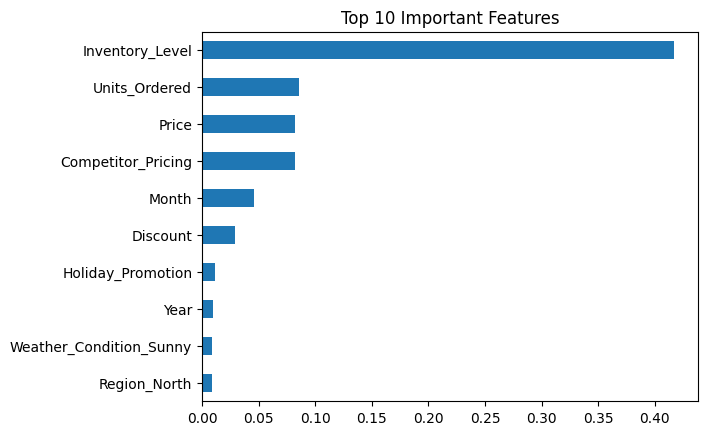

In [ ]:
## 32. Feature Importance
imp = pd.Series(rf.feature_importances_, index=X.columns)
imp.sort_values().tail(10).plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()

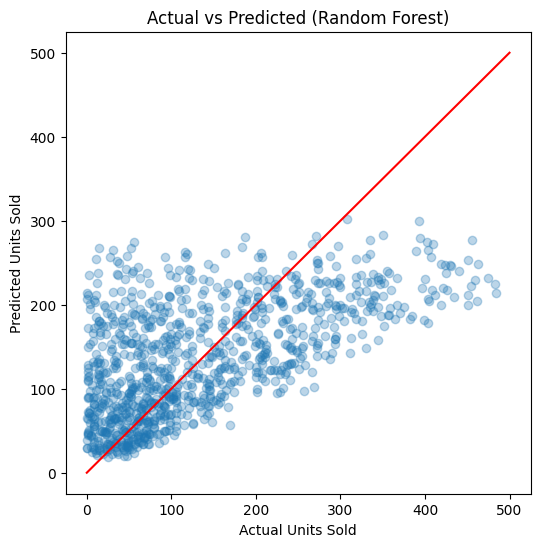

In [ ]:
## 33. Actual vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test.iloc[:1000], rf_pred[:1000], alpha=0.3)
plt.plot([0, 500], [0, 500], color="red")
plt.xlabel("Actual Units Sold")
plt.ylabel("Predicted Units Sold")
plt.title("Actual vs Predicted (Random Forest)")
plt.show()

In [ ]:
## 26. Save the Cleaned Data
df.to_csv("cleaned_retail_data.csv", index=False)

from google.colab import files
files.download("cleaned_retail_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>